# EDA 3 · ¿Qué mejoró al regenerar los datos de clientes?

Cada fila representa un cliente. Exploramos `clientes.csv` y retomamos tres preguntas del EDA2 sobre gasto, segmentos y satisfacción. Usamos `dataset_dummy.xlsx` como referencia para calcular las mismas medidas en ambas poblaciones. La comparación es entre distribuciones y asociaciones, sin emparejar clientes por identificador.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)

clientes = pd.read_csv("clientes.csv")
original = pd.read_excel("dataset_dummy.xlsx")
versiones = {"Original": original, "Regenerado": clientes}
display(clientes.head())

,customer_id,edad,segmento,antiguedad_meses,ingreso_mensual,tarjeta_santander,uso_tarjeta_pct,transacciones_mes,gasto_mensual,ecommerce_pct,pagos_puntuales_pct,app_logins_mes,nps,satisfaccion,abandono_riesgo,activacion_promos_pct
0,SYN-00000000,68,Mass,18,13537.74,Free,0.00,0,0.00,0.00,76.76,0,10,4.55,0.114005,14.32
1,SYN-00000001,28,Select,78,44468.56,Fiesta Rewards Oro,63.40,17,16887.29,36.28,81.92,10,6,3.08,0.533066,51.28
2,SYN-00000002,65,Premier,128,44612.29,LikeU,61.16,19,12298.70,39.08,68.32,11,10,3.60,0.277450,42.41
3,SYN-00000003,38,Premier,65,24868.27,Aeromexico Blanca,64.70,19,11866.07,24.08,84.08,8,3,2.10,0.466886,47.30
4,SYN-00000004,56,Premier,2,41854.58,LikeU,72.15,18,10031.22,74.11,100.00,13,8,3.83,0.287273,42.62


## 1. Cobertura y consistencia

Revisamos identificadores, faltantes y rangos antes de interpretar las asociaciones. Para clientes sin transacciones en el mes, comprobamos si el gasto registrado en ese mismo periodo también es cero.

In [2]:
perfil = pd.DataFrame({
    "Tipo": clientes.dtypes.astype(str),
    "Faltantes": clientes.isna().sum(),
    "Valores distintos": clientes.nunique(),
})
numericas = clientes.select_dtypes("number")
perfil[["Mínimo", "Mediana", "Máximo"]] = numericas.agg(["min", "median", "max"]).T
print(f"{len(clientes):,} filas · {clientes.shape[1]} variables · "
      f"{clientes.customer_id.nunique():,} identificadores únicos")
display(perfil.style.format({c: "{:,.2f}" for c in ["Mínimo", "Mediana", "Máximo"]}, na_rep="—"))

sin_movimientos = clientes.transacciones_mes.eq(0)
sin_gasto = clientes.gasto_mensual.eq(0)
print(f"Sin transacciones y sin gasto: {(sin_movimientos & sin_gasto).sum():,} clientes.")
print(f"Solo una de las dos variables en cero: {(sin_movimientos ^ sin_gasto).sum():,} clientes.")

10,000 filas · 16 variables · 10,000 identificadores únicos


,Tipo,Faltantes,Valores distintos,Mínimo,Mediana,Máximo
customer_id,object,0,10000,—,—,—
edad,int64,0,58,18.00,46.00,75.00
segmento,object,0,3,—,—,—
antiguedad_meses,int64,0,181,0.00,80.00,180.00
ingreso_mensual,float64,0,6315,"4,967.63","27,265.12","193,139.02"
tarjeta_santander,object,0,9,—,—,—
uso_tarjeta_pct,float64,0,4828,0.00,61.61,100.00
transacciones_mes,int64,0,47,0.00,18.00,50.00
gasto_mensual,float64,0,9137,0.00,"10,235.34","430,659.12"
ecommerce_pct,float64,0,5559,0.00,47.21,100.00


Sin transacciones y sin gasto: 827 clientes.
Solo una de las dos variables en cero: 0 clientes.


Las 16 columnas están completas y los 10,000 identificadores son únicos. Los cuatro porcentajes se mantienen entre 0 y 100. Los 827 clientes sin transacciones registran gasto cero y todos los clientes con transacciones registran gasto positivo.

## 2. ¿Qué variables se relacionan ahora?

La matriz muestra la correlación lineal de Pearson entre las 13 variables numéricas del archivo regenerado. El signo indica el sentido de la relación y la magnitud indica su intensidad. La tabla recupera tres pares que el EDA2 había identificado por su interpretación.

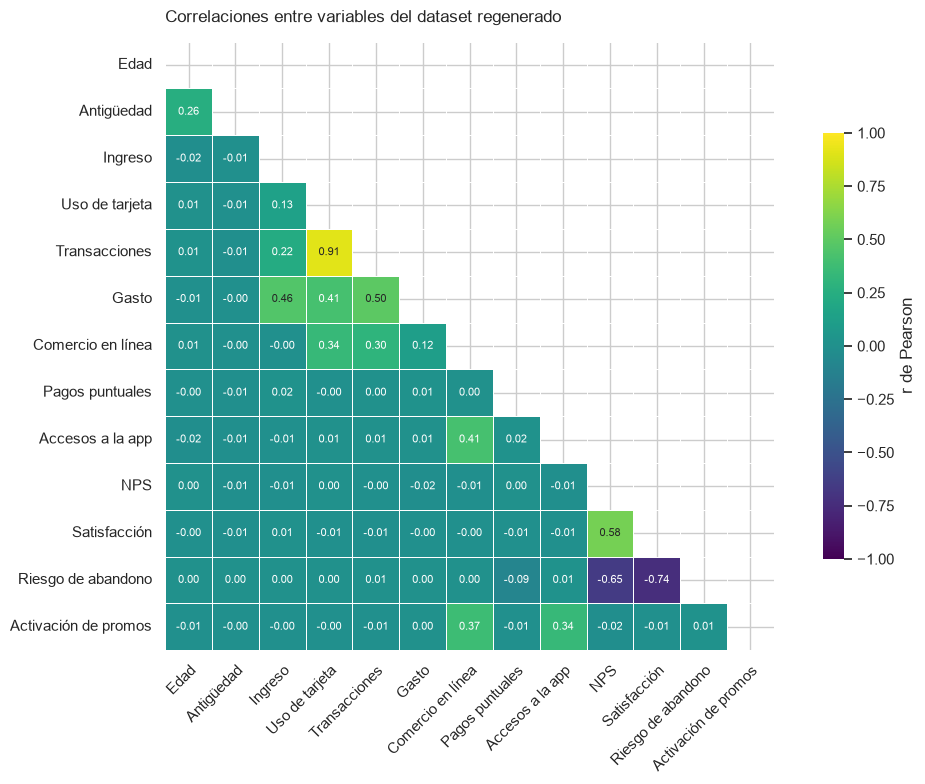

,Original,Regenerado
Ingreso y gasto,0.016,0.457
Transacciones y gasto,0.007,0.497
Satisfacción y riesgo,-0.016,-0.740


In [9]:
etiquetas = {
    "edad": "Edad", "antiguedad_meses": "Antigüedad", "ingreso_mensual": "Ingreso",
    "uso_tarjeta_pct": "Uso de tarjeta", "transacciones_mes": "Transacciones",
    "gasto_mensual": "Gasto", "ecommerce_pct": "Comercio en línea",
    "pagos_puntuales_pct": "Pagos puntuales", "app_logins_mes": "Accesos a la app",
    "nps": "NPS", "satisfaccion": "Satisfacción", "abandono_riesgo": "Riesgo de abandono",
    "activacion_promos_pct": "Activación de promos",
}
correlaciones = {nombre: datos[numericas.columns].corr() for nombre, datos in versiones.items()}
matriz = correlaciones["Regenerado"].rename(index=etiquetas, columns=etiquetas)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(matriz, mask=np.triu(np.ones(matriz.shape, dtype=bool)), ax=ax,
            cmap="viridis", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.4, square=True,
            cbar_kws={"label": "r de Pearson", "shrink": 0.70})
ax.set_title("Correlaciones entre variables del dataset regenerado", loc="left", pad=14)
plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()

pares = {
    "Ingreso y gasto": ("ingreso_mensual", "gasto_mensual"),
    "Transacciones y gasto": ("transacciones_mes", "gasto_mensual"),
    "Satisfacción y riesgo": ("satisfaccion", "abandono_riesgo"),
}
comparacion_r = pd.DataFrame({
    nombre: {par: corr.loc[a, b] for par, (a, b) in pares.items()}
    for nombre, corr in correlaciones.items()
})
display(comparacion_r.style.format("{:.3f}"))

Los tres pares pasaron de correlaciones cercanas a cero a asociaciones visibles. El vínculo más fuerte de la matriz regenerada aparece entre uso de tarjeta y número de transacciones (*r* = 0.91). Ambas variables podrían recoger parte de la misma actividad mensual.

## 3. Tres relaciones bajo la lupa

### ¿Cómo varía el gasto con el ingreso?

Se divide a los clientes en diez grupos del mismo tamaño según su ingreso. Para cada grupo, la línea muestra el gasto mediano y las bandas muestran qué tan disperso es el gasto: la oscura cubre al 50 % central y la clara al 80 %. Todo se calcula sobre la base completa.

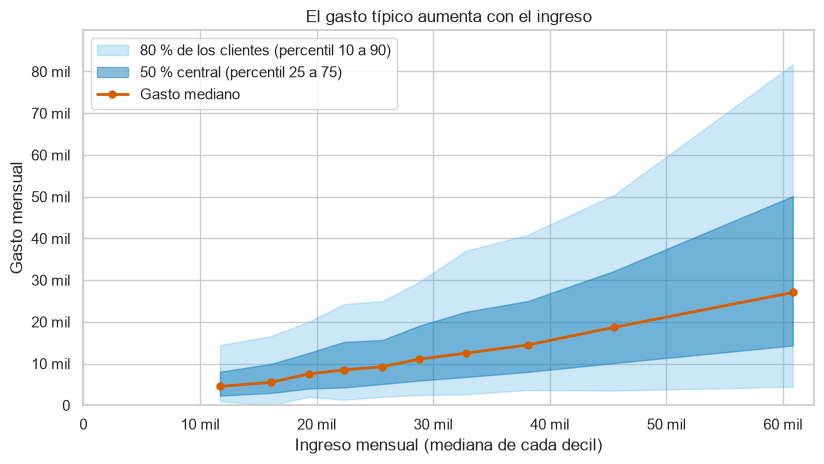

Gasto máximo en la base: 430,659.12.


In [14]:
x, y = "ingreso_mensual", "gasto_mensual"
grupo = pd.qcut(clientes[x], 10, labels=False, duplicates="drop")
ingreso_tipico = clientes.groupby(grupo)[x].median()
gasto = clientes.groupby(grupo)[y].quantile([0.10, 0.25, 0.50, 0.75, 0.90]).unstack()

fig, ax = plt.subplots(figsize=(8.4, 4.8))
ax.fill_between(ingreso_tipico, gasto[0.10], gasto[0.90], color="#56B4E9", alpha=0.30,
                label="80 % de los clientes (percentil 10 a 90)")
ax.fill_between(ingreso_tipico, gasto[0.25], gasto[0.75], color="#0072B2", alpha=0.45,
                label="50 % central (percentil 25 a 75)")
ax.plot(ingreso_tipico, gasto[0.50], "o-", color="#D55E00", lw=2, markersize=5,
        label="Gasto mediano")
ax.set(xlabel="Ingreso mensual (mediana de cada decil)", ylabel="Gasto mensual",
       xlim=(0, ingreso_tipico.max() * 1.03), ylim=(0, gasto[0.90].max() * 1.1),
       title="El gasto típico aumenta con el ingreso")
miles = FuncFormatter(lambda valor, _: f"{valor / 1000:g} mil" if valor else "0")
ax.xaxis.set_major_formatter(miles)
ax.yaxis.set_major_formatter(miles)
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
print(f"Gasto máximo en la base: {clientes[y].max():,.2f}.")

El gasto mediano sube con el ingreso, aunque clientes con ingresos similares presentan gastos muy distintos. Al revisar la base completa, el porcentaje que gasta más que su ingreso mensual sube de 9.03 % a 12.20 %. Queda por aclarar cómo se generaron esos montos y si existen otras fuentes de recursos.

### ¿Se distinguen los segmentos por ingreso?

Las cajas abarcan el 50 % central de cada segmento. La línea interior marca la mediana y los puntos muestran observaciones fuera de los bigotes.

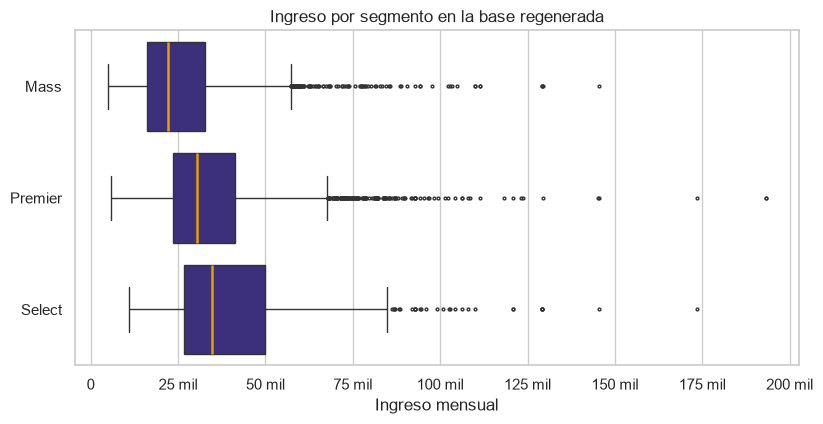

,Original,Regenerado
Mediana de ingreso,,
Mass,"27,215","22,004"
Premier,"27,105","30,281"
Select,"26,019","34,582"


In [12]:
orden = ["Mass", "Premier", "Select"]
fig, ax = plt.subplots(figsize=(8.4, 4.4))
sns.boxplot(data=clientes, x="ingreso_mensual", y="segmento", order=orden,
            color="#328", fliersize=2, linewidth=1, ax=ax,
            medianprops={"color": "#E69F00", "linewidth": 1.8})
ax.xaxis.set_major_formatter(miles)
ax.set(xlabel="Ingreso mensual", ylabel="", title="Ingreso por segmento en la base regenerada")
fig.tight_layout()
plt.show()

ingresos = pd.DataFrame({
    nombre: datos.groupby("segmento").ingreso_mensual.median()
    for nombre, datos in versiones.items()
}).reindex(orden)
display(ingresos.rename_axis("Mediana de ingreso").style.format("{:,.0f}"))

En el original, los tres segmentos tenían medianas cercanas a 27 mil. En la base regenerada se ordenan de Mass a Premier y Select. Las cajas se traslapan incluso entre Mass y Select, así que un mismo ingreso puede aparecer en los tres segmentos.

### ¿Cómo cambia el riesgo asignado según la satisfacción?

Agrupamos la satisfacción con los cortes del EDA2. El primer grupo incluye ambos extremos y los siguientes incluyen el extremo derecho. Cada caja muestra la distribución del puntaje de riesgo dentro del intervalo.

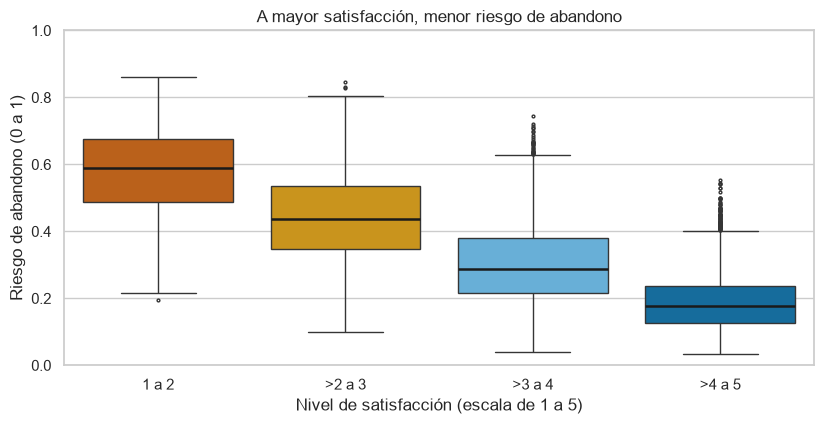

,Original,Regenerado
Satisfacción,,
1 a 2,0.503,0.579
>2 a 3,0.501,0.443
>3 a 4,0.492,0.305
>4 a 5,0.493,0.191


In [13]:
grupos = ["1 a 2", ">2 a 3", ">3 a 4", ">4 a 5"]
def tramo_satisfaccion(datos):
    return pd.cut(datos.satisfaccion, bins=[1, 2, 3, 4, 5], labels=grupos, include_lowest=True)

fig, ax = plt.subplots(figsize=(8.4, 4.4))
# Paleta Okabe-Ito (apta para daltonismo): cálido = más riesgo, frío = menos riesgo
paleta = ["#D55E00", "#E69F00", "#56B4E9", "#0072B2"]
sns.boxplot(x=tramo_satisfaccion(clientes), y=clientes.abandono_riesgo, hue=tramo_satisfaccion(clientes),
            palette=paleta, legend=False, fliersize=2, linewidth=1, ax=ax,
            medianprops={"color": "#1a1a1a", "linewidth": 1.8})
ax.set(xlabel="Nivel de satisfacción (escala de 1 a 5)", ylabel="Riesgo de abandono (0 a 1)", ylim=(0, 1),
       title="A mayor satisfacción, menor riesgo de abandono")
fig.tight_layout()
plt.show()

riesgo = pd.DataFrame({
    nombre: datos.groupby(tramo_satisfaccion(datos), observed=False).abandono_riesgo.mean()
    for nombre, datos in versiones.items()
})
display(riesgo.rename_axis("Satisfacción").style.format("{:.3f}"))

En el original, el riesgo promedio rondaba 0.50 en los cuatro grupos. En el regenerado baja en cada intervalo, de 0.579 a 0.191 entre los extremos. La variación dentro de cada caja muestra que clientes con satisfacción parecida reciben puntajes distintos. El archivo contiene un puntaje sintético y carece de un indicador de abandono observado con el que evaluar su precisión.

## 4. ¿Qué mejoró respecto al EDA2?

Las dos versiones se evalúan con los mismos indicadores. Para la antigüedad retomamos la aproximación del EDA2, que resta los meses de antigüedad divididos entre 12 a la edad en años cumplidos.

In [7]:
cierre = comparacion_r.apply(lambda serie: serie.map(lambda r: f"r = {r:.3f}"))
for nombre, datos in versiones.items():
    cierre.loc["Ingreso mediano · Mass / Premier / Select", nombre] = " / ".join(
        f"{valor:,.0f}" for valor in ingresos[nombre])
    cierre.loc["Riesgo medio · satisfacción baja / alta", nombre] = (
        f"{riesgo.loc[grupos[0], nombre]:.3f} / {riesgo.loc[grupos[-1], nombre]:.3f}")
    edad_estimada = datos.edad - datos.antiguedad_meses / 12
    cierre.loc["Edad estimada al alta inferior a 18", nombre] = f"{edad_estimada.lt(18).mean():.2%}"
    cierre.loc["Gasto mensual superior al ingreso", nombre] = (
        f"{datos.gasto_mensual.gt(datos.ingreso_mensual).mean():.2%}")
cierre["Lectura"] = [
    "El gasto tiende a crecer con el ingreso.",
    "Los clientes con más transacciones tienden a gastar más.",
    "La satisfacción se asocia con menor riesgo asignado.",
    "Las medianas se separan y las distribuciones se traslapan.",
    "La diferencia de riesgo entre los extremos se amplía.",
    "Desaparecen los casos señalados por esta aproximación.",
    "Aumenta la frecuencia. Conviene revisar la regla de generación.",
]
display(cierre.rename_axis("Indicador"))

,Original,Regenerado,Lectura
Indicador,,,
Ingreso y gasto,r = 0.016,r = 0.457,El gasto tiende a crecer con el ingreso.
Transacciones y gasto,r = 0.007,r = 0.497,Los clientes con más transacciones tienden a g...
Satisfacción y riesgo,r = -0.016,r = -0.740,La satisfacción se asocia con menor riesgo asi...
Ingreso mediano · Mass / Premier / Select,"27,215 / 27,105 / 26,019","22,004 / 30,281 / 34,582",Las medianas se separan y las distribuciones s...
Riesgo medio · satisfacción baja / alta,0.503 / 0.493,0.579 / 0.191,La diferencia de riesgo entre los extremos se ...
Edad estimada al alta inferior a 18,14.09%,0.00%,Desaparecen los casos señalados por esta aprox...
Gasto mensual superior al ingreso,9.03%,12.20%,Aumenta la frecuencia. Conviene revisar la reg...


La regeneración corrigió dos problemas centrales del EDA2. El gasto y el riesgo asignado ahora guardan relación con otras características del cliente, y los segmentos distinguen niveles típicos de ingreso con traslape entre grupos. También desaparecieron los casos de antigüedad que situaban la contratación antes de los 18 años según la aproximación utilizada.

El resultado pendiente de explicar es el aumento de clientes cuyo gasto supera su ingreso mensual. Con los criterios del generador aún por conocer, la evidencia permite concluir que **mejoró la coherencia interna en las relaciones examinadas**. Para evaluar qué tan representativos son estos patrones de una cartera real haría falta una referencia externa.